# Stage 8: cylindrical topological echelle

## tl;dr

The geometry is a true cylinder, but the frozen combined score does not pass the inference-utility gate. The result is **geometry_only**, not a positive topological detection claim.


## Context and methods

Run `TA-S08-ECHELLE-R001` uses 24 sealed Stage 4 simulation cells, 12 held-out even-numbered evaluation cells, and a Stage 6 ACF-seeded 15-trial spacing grid. The score, null, interval, and utility thresholds are frozen in `configs/stage8_echelle.yaml`. No population spectra or final holdout are accessed.

Missing echelle vertices are omitted; phase wraps but order does not. Finite normalized H0 plus circular ridge coherence enters the score; essential H1 is kept for mathematical validation.


In [1]:
import csv
import json
from pathlib import Path

root = Path('results/stage8')
def read_csv(name):
    with (root / name).open(newline='') as handle:
        return list(csv.DictReader(handle))

bench = read_csv('paired_benchmark.csv')
nulls = read_csv('null_maxima.csv')
intervals = read_csv('intervals.csv')
gate = json.loads(Path('reports/stage8/G8_ACCEPTANCE.json').read_text())
suite = json.loads((root / 'diagram_suite.json').read_text())
print(gate['decision'], len(bench), len(nulls), len(intervals), suite['essential_h1'], suite['rectangle_essential_h1'])


geometry_only 144 288 12 1 0


## Results: paired controls and multiplicity

Recompute the gate's detectable-subset accuracies and a family-wise null p-value directly from the saved CSV files. The published mode-ratio audit is a check on formulae, not a blind ridge inference.


In [2]:
selected = [row for row in bench if row['role'] == 'evaluation' and row['detectable'] == 'true']
for method in ('topology', 'graph', 'conventional', 'hough', 'acf', 'psps'):
    rows = [row for row in selected if row['method'] == method]
    print(method, sum(row['correct'] == 'true' for row in rows), '/', len(rows))
example = next(row for row in bench if row['cell_id'] == 'F4-004' and row['method'] == 'topology')
example_nulls = [float(row['maximum_statistic']) for row in nulls if row['cell_id'] == 'F4-004']
pvalue = (1 + sum(value >= float(example['score']) for value in example_nulls)) / (len(example_nulls) + 1)
assert abs(pvalue - float(example['max_statistic_pvalue'])) < 1e-8
assert gate['decision'] == 'geometry_only' and suite['essential_h1'] == 1
print('F4-004 max-statistic p-value', pvalue, 'G8', gate['decision'])


topology 1 / 5
graph 3 / 5
conventional 3 / 5
hough 2 / 5
acf 5 / 5
psps 1 / 5
F4-004 max-statistic p-value 0.04 G8 geometry_only


## Paired accuracy figure

This compact plot reuses the project-wide academic style and the same governed benchmark rows. The five publication SVGs live under `reports/stage8/figures/`.


Decision: geometry_only topology increment: -0.4


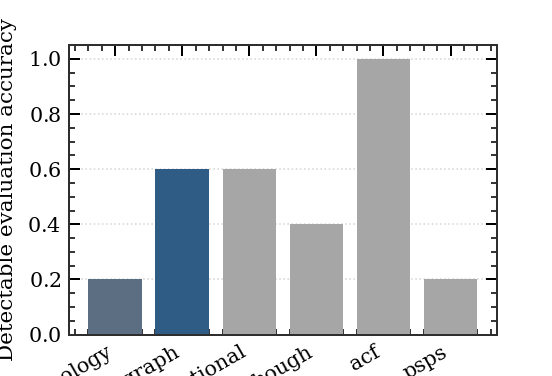

In [3]:
import matplotlib.pyplot as plt

from topoastero.style import FIGSIZE, data_color, style_axes, topoastero_style

methods = ('topology', 'graph', 'conventional', 'hough', 'acf', 'psps')
rates = [sum(row['correct'] == 'true' for row in selected if row['method'] == method) / sum(row['method'] == method for row in selected) for method in methods]
with topoastero_style():
    fig, ax = plt.subplots(figsize=FIGSIZE['single'])
    ax.bar(range(6), rates, color=[data_color('spectrum'), data_color('background')] + ['0.65'] * 4)
    ax.set_xticks(range(6), methods, rotation=30, ha='right')
    style_axes(ax, ylabel='Detectable evaluation accuracy', ylim=(0, 1.05))
    plt.show()
print('Decision:', gate['decision'], 'topology increment:', round(gate['alias_accuracy_topology'] - gate['alias_accuracy_graph'], 3))


## Takeaways and limits

The cylinder seam and localized essential loop are exact topological facts, not evidence that this finite-H0 estimator recovers the correct alias. The locked simulation benchmark fails alias accuracy, 90% interval coverage, and graph-only increment; therefore only geometric software and a scoped negative result are retained. The ridge-angle proxy needs an external degree anchor, and five-point ratios require identified frequencies. Stage 7 delay PH remains outside the critical path.
